In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
plt.style.use('ggplot')
pd.set_option("max_columns",200)

In [3]:
df=pd.read_csv("/content/Telco-Customer-Churn-cleaned.csv")

In [ ]:
df.head()
df.tail()
df.dtypes
df.describe()
df.describe(include="object")
df.columns
df.isnull().sum()
df.duplicated().sum()
df.shape
df.nunique()
df.memory_usage(deep=True)

,Column1,Gender,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,2,3,2,2,2,2,2,2,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,4072,3096,5024,4614,4621,4999,4336,4311,3875,4171,2365,5174


In [ ]:
df['Gender'].value_counts()
df['Gender'].value_counts(normalize=True)
df['Total Charges'].value_counts(dropna=False)


,count
Total Charges,
0.00,11
20.20,11
19.75,9
20.05,8
19.90,8
...,...
130.15,1
3211.90,1
7843.55,1


In [ ]:
df["Tenure"].mean() #32.37114865824223
df["Tenure"].median() #29.0
df["Tenure"].mode() #1
df["Tenure"].min() #0
df["Tenure"].max() #72
df["Tenure"].std() #24.55948102309423
df["Tenure"].skew() #0.2395397495619829

df["Monthly Charges"].mean() #64.76169246059918
df["Monthly Charges"].median() #70.35
df["Monthly Charges"].mode() #20.05
df["Monthly Charges"].min() #18.25
df["Monthly Charges"].max() #118.75
df["Monthly Charges"].std() #30.09004709767854
df["Monthly Charges"].skew() #-0.22052443394398033

df["Total Charges"].mean() #2279.7343035638223
df["Total Charges"].median() #1394.55
df["Total Charges"].mode()  #	Total Charges : 0.0, 20.2
df["Total Charges"].min() #0.0
df["Total Charges"].max() #8684.8
df["Total Charges"].std() #2266.7944696890195
df["Total Charges"].skew() #0.963234654832277
df[['Tenure', 'Monthly Charges', 'Total Charges']].describe()

,Tenure,Monthly Charges,Total Charges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [7]:
df[['Tenure', 'Monthly Charges', 'Total Charges']].var()

,0
Tenure,6.031681e+02
Monthly Charges,9.054109e+02
Total Charges,5.138357e+06


In [8]:
df.groupby('Churn')[
    ['Tenure', 'Monthly Charges', 'Total Charges']
].agg(['mean', 'median', 'std'])

Tenure                   Monthly Charges                     \
            mean median        std            mean  median        std   
Churn                                                                   
No     37.569965   38.0  24.113777       61.265124  64.425  31.092648   
Yes    17.979133   10.0  19.531123       74.441332  79.650  24.666053   

      Total Charges                         
               mean    median          std  
Churn                                       
No      2549.911442  1679.525  2329.954215  
Yes     1531.796094   703.550  1890.822994

In [9]:
#univariate Analysis
#df['Gender'].value_counts()
categorical_cols=df.select_dtypes(include='object').columns
for col in categorical_cols:
  print("\n",col)
  print(df[col].value_counts())



 Column1
Column1
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

 Gender
Gender
Male      3555
Female    3488
Name: count, dtype: int64

 Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

 Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

 Phone Service
Phone Service
Yes    6361
No      682
Name: count, dtype: int64

 Multiple Lines
Multiple Lines
No     4072
Yes    2971
Name: count, dtype: int64

 Internet Service
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

 Online Security
Online Security
No     5024
Yes    2019
Name: count, dtype: int64

 Online Backup
Online Backup
No     4614
Yes    2429
Name: count, dtype: int64

 Device Protection
Device Protection
No     4621
Yes    2422
Name: count, dtype: int64

 Tech Support
T

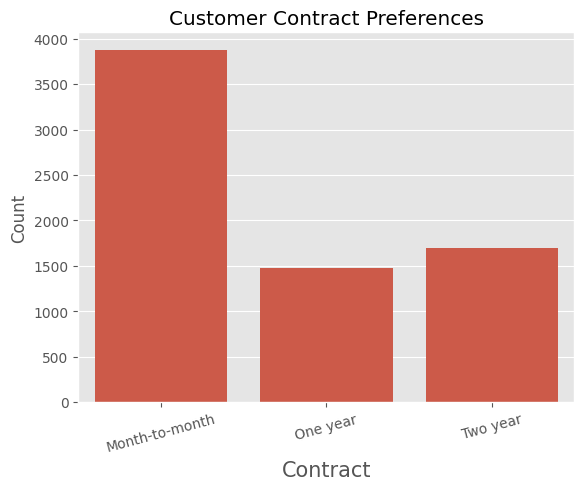

In [10]:
sns.countplot(data=df,x='Contract')
plt.title("Customer Contract Preferences")
plt.xlabel("Contract",fontsize=15)
plt.ylabel("Count")
plt.xticks(rotation=15)
plt.show()

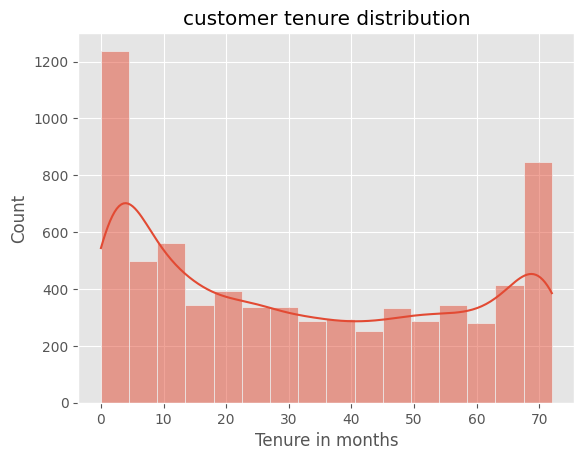

In [11]:
sns.histplot(data=df,x='Tenure',kde="True")
plt.title("customer tenure distribution")
plt.xlabel("Tenure in months")
plt.show()

In [12]:
#Bivariate Analysis
pd.crosstab(df['Churn'],df['Contract'])

Contract,Month-to-month,One year,Two year
Churn,,,
No,2220,1307,1647
Yes,1655,166,48


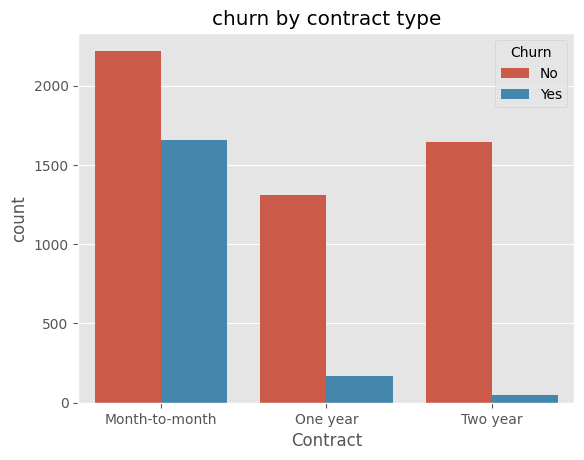

In [13]:
sns.countplot(data=df,
              x='Contract',
              hue='Churn')
plt.title('churn by contract type')
plt.show()

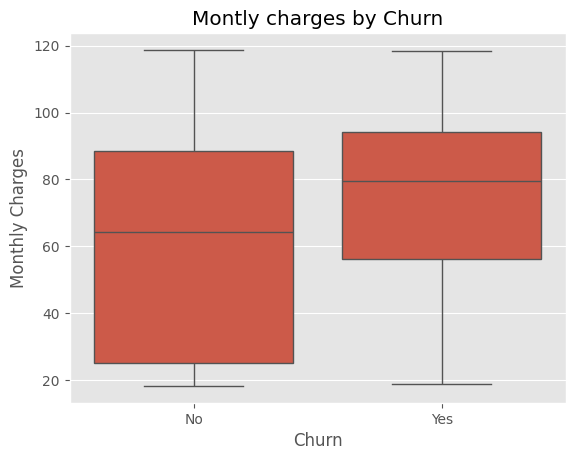

In [14]:
sns.boxplot(data=df,x='Churn',y='Monthly Charges')
plt.title("Montly charges by Churn")
plt.show()

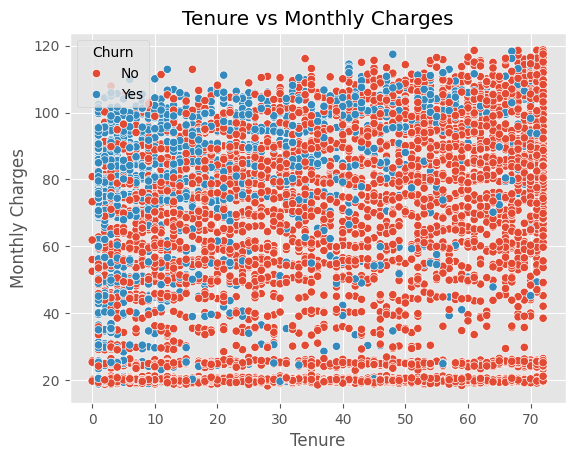

In [15]:
sns.scatterplot(data=df,x="Tenure",y="Monthly Charges",hue="Churn")
plt.title("Tenure vs Monthly Charges")
plt.show()

In [16]:
numeric_df=df.select_dtypes(include='number')
correlation=numeric_df.corr()
print(correlation)

                 Senior Citizen    Tenure  Monthly Charges  Total Charges
Senior Citizen         1.000000  0.016567         0.220173       0.103006
Tenure                 0.016567  1.000000         0.247900       0.826178
Monthly Charges        0.220173  0.247900         1.000000       0.651174
Total Charges          0.103006  0.826178         0.651174       1.000000


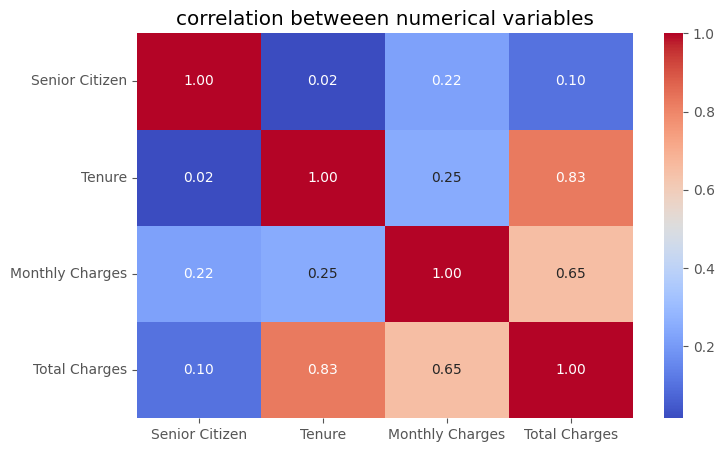

In [17]:
plt.figure(figsize=(8,5))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt='.2f')
plt.title('correlation betweeen numerical variables')
plt.show()

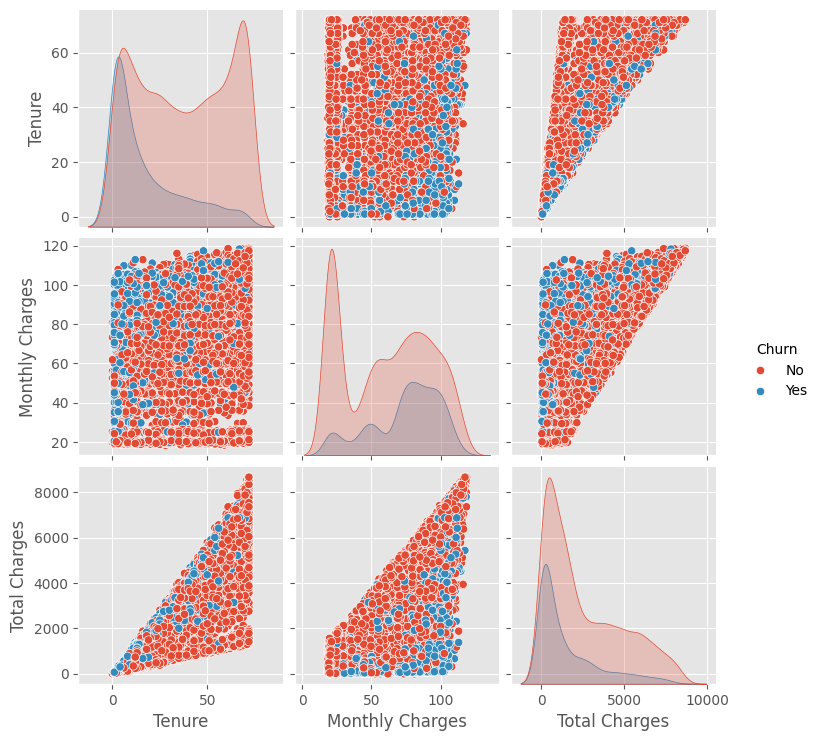

In [18]:
sns.pairplot(df[['Tenure','Monthly Charges','Total Charges','Churn']],hue='Churn')
plt.show()

In [19]:
#outliers
columns = ['Tenure', 'Monthly Charges', 'Total Charges']

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outlier count:", len(outliers))


Column: Tenure
Lower limit: -60.0
Upper limit: 124.0
Outlier count: 0

Column: Monthly Charges
Lower limit: -46.02499999999999
Upper limit: 171.375
Outlier count: 0

Column: Total Charges
Lower limit: -4683.525
Upper limit: 8868.675
Outlier count: 0


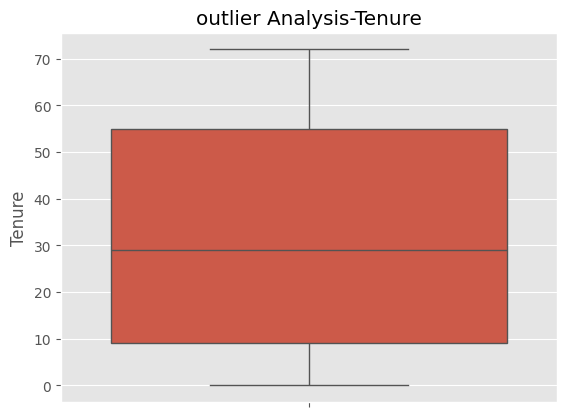

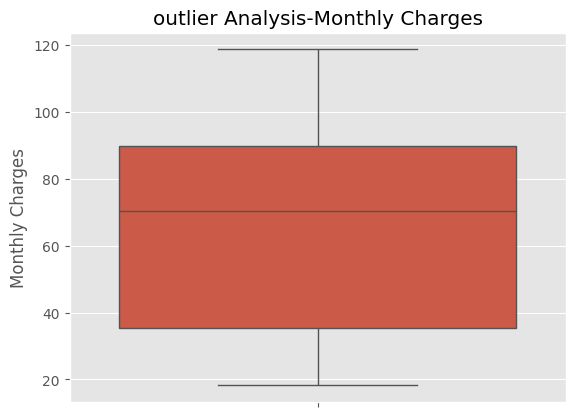

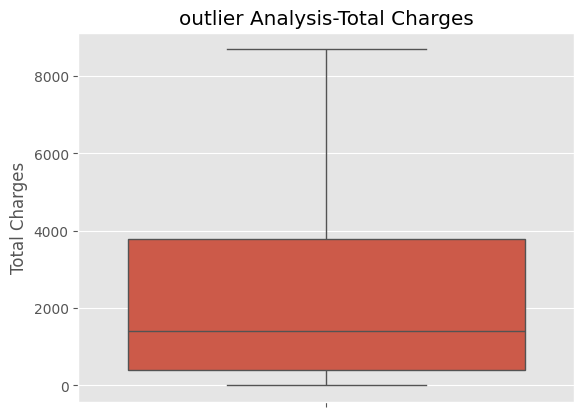

In [20]:
for col in columns:
  sns.boxplot(data=df,y=col)
  plt.title(f'outlier Analysis-{col}')
  plt.show()

In [21]:
pd.crosstab(df['Churn'],df['Senior Citizen'])

Senior Citizen,0,1
Churn,,
No,4508,666
Yes,1393,476


In [22]:
#pd.crosstab(df['Churn'],df['Senior Citizen'],normalize='index')*100
pd.crosstab(df['Churn'],df['Senior Citizen'],normalize='columns')*100

Senior Citizen,0,1
Churn,,
No,76.393832,58.318739
Yes,23.606168,41.681261


In [23]:
pd.crosstab(df['Churn'],df['Gender'],normalize="index")*100

Gender,Female,Male
Churn,,
No,49.265559,50.734441
Yes,50.240770,49.759230


In [24]:
pd.crosstab(df['Churn'],df['Gender'],normalize="columns")*100

Gender,Female,Male
Churn,,
No,73.079128,73.839662
Yes,26.920872,26.160338


In [25]:
df.groupby('Churn')['Monthly Charges'].mean()

,Monthly Charges
Churn,
No,61.265124
Yes,74.441332


Data Analysis & Business Questions

In [26]:
#count the customers who churned
churn_count=df['Churn'].value_counts()
print(churn_count)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [27]:
#calculate percentage if each churn
churn_percentage=df['Churn'].value_counts(normalize=True)*100
print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [28]:
#overall churn rate
churn_rate = (df['Churn'] == 'Yes').mean() * 100
print("Overall Churn Rate:", round(churn_rate, 2), "%")

Overall Churn Rate: 26.54 %


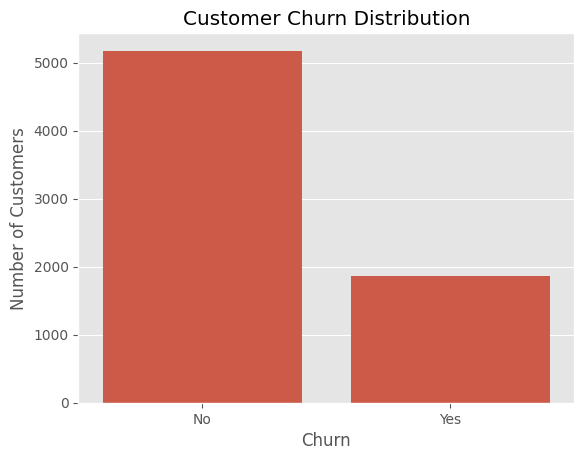

In [29]:
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [30]:
contract_churn=pd.crosstab(df['Churn'],df['Contract'],normalize='index')*100
print(contract_churn)

Contract  Month-to-month   One year   Two year
Churn                                         
No             42.906842  25.260920  31.832238
Yes            88.550027   8.881755   2.568218


In [37]:
contract_rate = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_rate)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


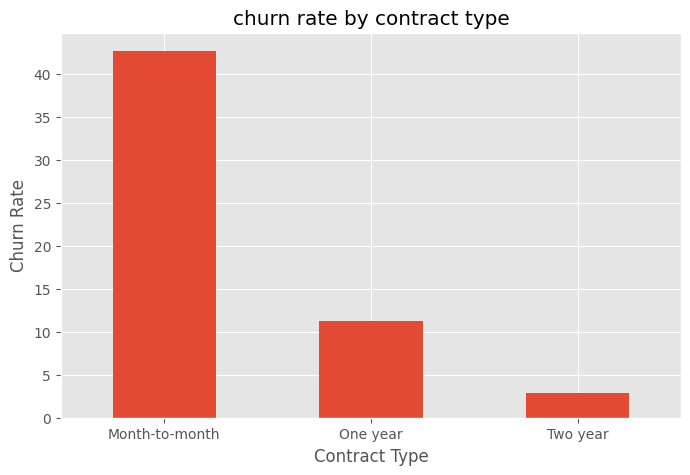

In [41]:
contract_rate.plot(kind='bar',
             figsize=(8,5))
plt.title("churn rate by contract type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.xticks(rotation=0)
plt.show()

In [38]:
contract_rate = contract_rate['Yes'].sort_values(ascending=False)
print(contract_rate)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Yes, dtype: float64


In [49]:
payment_churn=pd.crosstab(df['Payment Method'],df['Churn'])
print(payment_churn)

Churn                        No   Yes
Payment Method                       
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308


In [50]:
payment_rate = pd.crosstab(
    df['Payment Method'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_rate)

Churn                             No        Yes
Payment Method                                 
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [51]:
payment_rate = payment_rate['Yes'].sort_values(
    ascending=False
)

print(payment_rate)

Payment Method
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Yes, dtype: float64


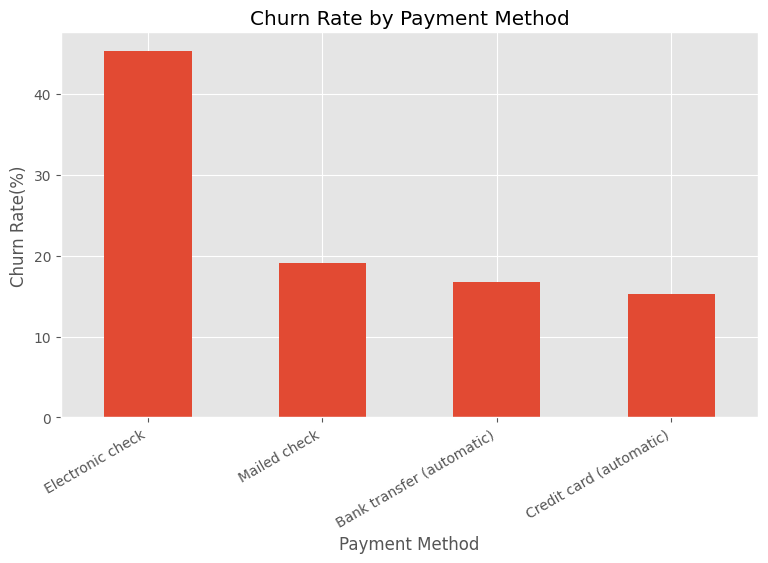

In [52]:
payment_rate.plot(kind="bar",figsize=(9,5))
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation=30,ha='right')
plt.show()

In [53]:
bins=[0,12,24,36,48,60,72]
labels=["0-12months","13-24months","25-36months","37-48months","49-60months","61-72months"]
df['Tenure_group']=pd.cut(df['Tenure'],bins=bins,labels=labels,include_lowest=True)

In [54]:
tenure_churn=pd.crosstab(df["Tenure_group"],df["Churn"])
print(tenure_churn)

Churn           No   Yes
Tenure_group            
0-12months    1149  1037
13-24months    730   294
25-36months    652   180
37-48months    617   145
49-60months    712   120
61-72months   1314    93


In [55]:
tenure_rate=tenure_churn["Yes"]
print(tenure_rate)

Tenure_group
0-12months     1037
13-24months     294
25-36months     180
37-48months     145
49-60months     120
61-72months      93
Name: Yes, dtype: int64


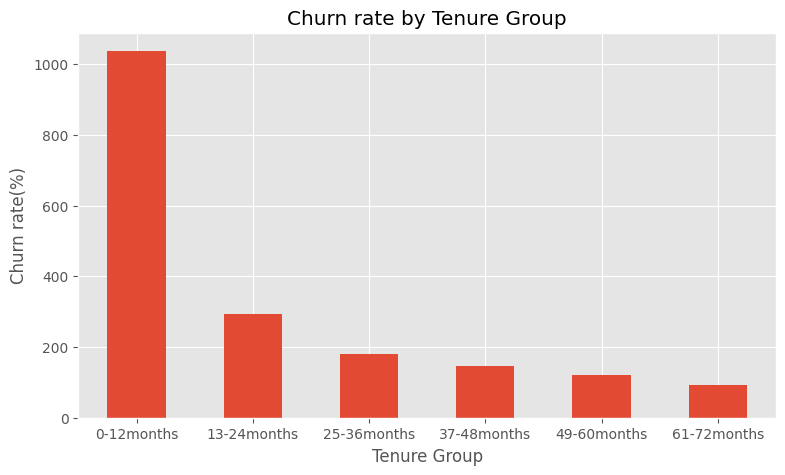

In [56]:
tenure_rate.plot(kind="bar",figsize=(9,5))
plt.title("Churn rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn rate(%)")
plt.xticks(rotation=0)
plt.show()

In [57]:
Senior_churn=pd.crosstab(df['Senior Citizen'],df['Churn'],normalize='index')*100
print(Senior_churn)


Churn                  No        Yes
Senior Citizen                      
0               76.393832  23.606168
1               58.318739  41.681261


In [58]:
print(Senior_churn['Yes'])


Senior Citizen
0    23.606168
1    41.681261
Name: Yes, dtype: float64


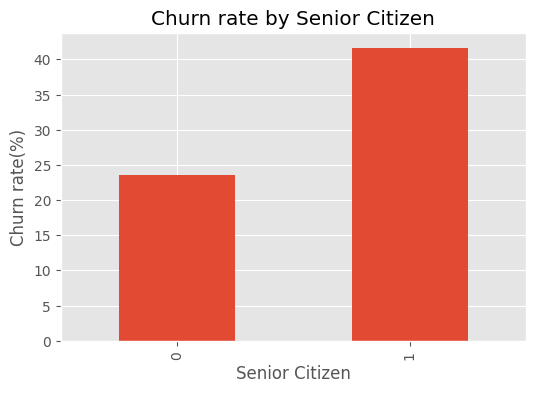

In [63]:
Senior_churn['Yes'].plot(kind="bar",figsize=(6,4))
plt.title("Churn rate by Senior Citizen")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn rate(%)")
plt.show()

In [65]:
def analyze_churn(column):
  result=pd.crosstab(df[column],df['Churn'],normalize='index')*100
  result=result.sort_values(by='Yes',ascending=False)
  print(f'\nChurn rate by {column}')
  print(result)

In [67]:
analyze_churn('Senior Citizen')
analyze_churn('Partner')
analyze_churn('Dependents')
analyze_churn('Phone Service')
analyze_churn('Internet Service')
analyze_churn('Online Security')
analyze_churn('Multiple Lines')
analyze_churn('Tech Support')


Churn rate by Senior Citizen
Churn                  No        Yes
Senior Citizen                      
1               58.318739  41.681261
0               76.393832  23.606168

Churn rate by Partner
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903

Churn rate by Dependents
Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237

Churn rate by Phone Service
Churn                 No        Yes
Phone Service                      
Yes            73.290363  26.709637
No             75.073314  24.926686

Churn rate by Internet Service
Churn                    No        Yes
Internet Service                      
Fiber optic       58.107235  41.892765
DSL               81.040892  18.959108
No                92.595020   7.404980

Churn rate by Online Security
Churn                   No        Yes
Online Security                      
No            

In [69]:
segment_analysis = pd.crosstab(
    [df['Senior Citizen'], df['Online Security']],
    df['Churn'],
    normalize='index'
) * 100

print(segment_analysis)

Churn                                  No        Yes
Senior Citizen Online Security                      
0              No               72.094140  27.905860
               Yes              86.701209  13.298791
1              No               52.093023  47.906977
               Yes              77.304965  22.695035


In [71]:
charges_analysis = df.groupby('Churn')['Monthly Charges'].mean()

print(charges_analysis)

Churn
No     61.265124
Yes    74.441332
Name: Monthly Charges, dtype: float64


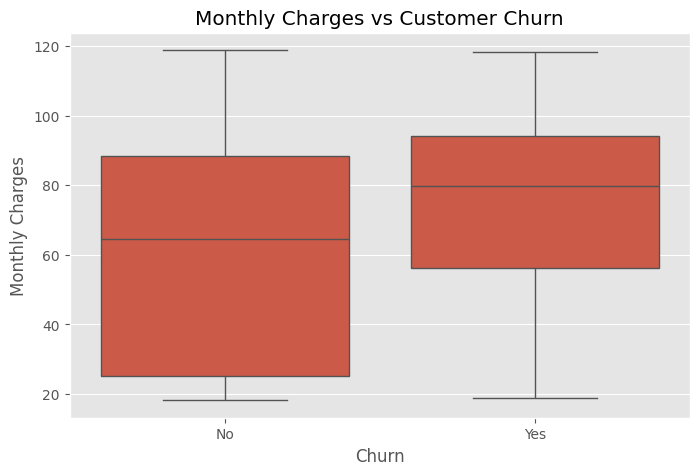

In [73]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='Monthly Charges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [75]:
df['ChargeGroup'] = pd.cut(
    df['Monthly Charges'],
    bins=4,
    labels=[
        'Low',
        'Medium-Low',
        'Medium-High',
        'High'
    ]
)

In [76]:
charge_churn = pd.crosstab(
    df['ChargeGroup'],
    df['Churn'],
    normalize='index'
) * 100

print(charge_churn)

Churn               No        Yes
ChargeGroup                      
Low          87.677725  12.322275
Medium-Low   78.503994  21.496006
Medium-High  63.187773  36.812227
High         66.418416  33.581584


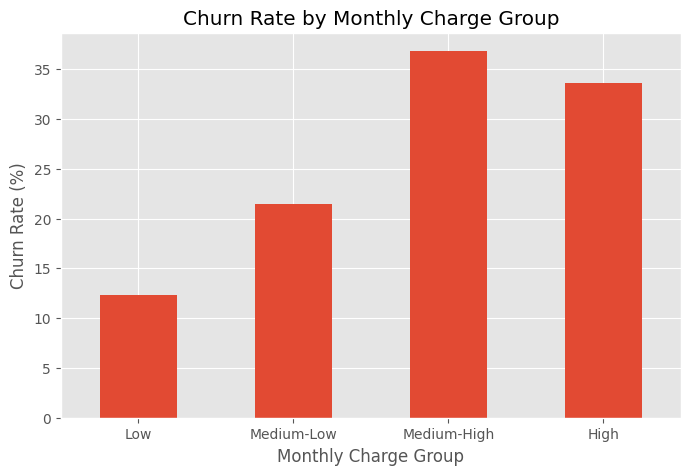

In [77]:
charge_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Churn Rate by Monthly Charge Group')
plt.xlabel('Monthly Charge Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()